In [16]:
import pandas as pd

url = "https://raw.githubusercontent.com/nanesarukhanyan/bass-model-homework/main/data/industrial_robots.csv"
df = pd.read_csv(url)
print(df)

    year  sales_k
0   2004       97
1   2005      120
2   2006      111
3   2007      114
4   2008      113
5   2009       60
6   2010      121
7   2011      166
8   2012      159
9   2013      178
10  2014      221
11  2015      254
12  2016      304
13  2017      400
14  2018      423
15  2019      387
16  2020      390
17  2021      526
18  2022      553
19  2023      541
20  2024      542


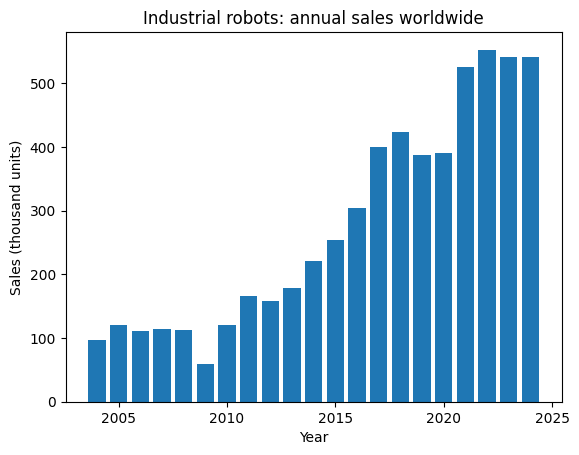

In [17]:
import matplotlib.pyplot as plt

plt.bar(df["year"], df["sales_k"])
plt.xlabel("Year")
plt.ylabel("Sales (thousand units)")
plt.title("Industrial robots: annual sales worldwide")
plt.show()

In [18]:
import numpy as np

def bass_sales(t, p, q, M):
    e = np.exp(-(p + q) * t)
    return M * ((p + q)**2 / p) * e / (1 + (q / p) * e)**2

In [19]:
t = df["year"] - df["year"].min() + 1   # 2004 -> 1, 2005 -> 2, ...
y = df["sales_k"]
print(t.head(), y.head())

0    1
1    2
2    3
3    4
4    5
Name: year, dtype: int64 0     97
1    120
2    111
3    114
4    113
Name: sales_k, dtype: int64


In [20]:
from scipy.optimize import curve_fit

popt, _ = curve_fit(
    bass_sales, t, y,
    p0=[0.01, 0.3, 10000],
    bounds=([1e-6, 1e-3, y.sum()], [1, 2, 1e6])
)
p, q, M = popt
print("p =", round(p, 5))
print("q =", round(q, 4))
print("M =", round(M))

p = 0.00345
q = 0.1614
M = 13934


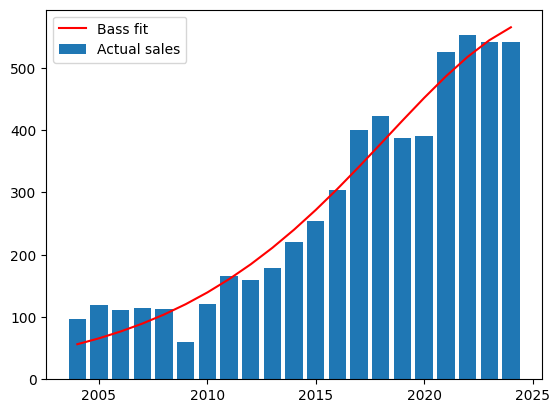

In [7]:
plt.bar(df["year"], y, label="Actual sales")
plt.plot(df["year"], bass_sales(t, p, q, M), "r", label="Bass fit")
plt.legend()
plt.show()

In [21]:
fitted = bass_sales(t, p, q, M)

ss_res = ((y - fitted) ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot
rmse = (ss_res / len(y)) ** 0.5

t_peak = np.log(q / p) / (p + q)
peak_year = df["year"].min() + t_peak - 1

print("R2   =", round(r2, 3))
print("RMSE =", round(rmse, 1), "thousand units")
print("Peak year =", round(peak_year, 1))
print("Total sold 2004-2024 =", y.sum(), "thousand")

R2   = 0.955
RMSE = 35.4 thousand units
Peak year = 2026.3
Total sold 2004-2024 = 5780 thousand


The humanoid robot scenarios are illustrative and depend on assumptions about initial shipments and total market potential. They are not direct forecasts of Unitree R1 sales. Independent market forecasts are used only as external benchmarks, not as confirmed outcomes.

      M = 10 million  M = 30 million  M = 100 million
2025         20000.0         20000.0          20000.0
2026         23440.0         23482.0          23496.0
2027         27452.0         27563.0          27602.0
2030         43833.0         44486.0          44718.0
2035         92575.0         97713.0          99603.0
2040        180955.0        208791.0         219985.0


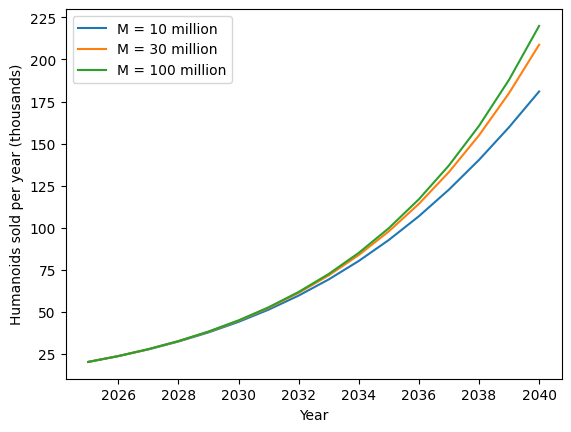

In [22]:
from scipy.optimize import brentq
import pandas as pd

q_la = q
sales_2025 = 20000
years = np.arange(2025, 2041)
t_h = np.arange(1, len(years) + 1)

results = {}
for M_h in [10e6, 30e6, 100e6]:
    p_h = brentq(lambda pp: bass_sales(1, pp, q_la, M_h) - sales_2025, 1e-8, 0.5)
    results[f"M = {M_h/1e6:.0f} million"] = bass_sales(t_h, p_h, q_la, M_h)

forecast = pd.DataFrame(results, index=years).round(0)
print(forecast.loc[[2025, 2026, 2027, 2030, 2035, 2040]])

for name, s in results.items():
    plt.plot(years, s / 1000, label=name)
plt.xlabel("Year")
plt.ylabel("Humanoids sold per year (thousands)")
plt.legend()
plt.show()

In [23]:
cumulative = forecast.cumsum()
print(cumulative.loc[[2025, 2026, 2027, 2030, 2035, 2040]])



      M = 10 million  M = 30 million  M = 100 million
2025         20000.0         20000.0          20000.0
2026         43440.0         43482.0          43496.0
2027         70892.0         71045.0          71098.0
2030        184392.0        185814.0         186316.0
2035        536711.0        551836.0         557321.0
2040       1246859.0       1342515.0        1379473.0



An initial nonlinear curve fit is to examine the historical industrial robot shipment series. A second estimation was then conducted by fitting the Bass cumulative-adoption curve and calculating annual predicted shipments as differences between consecutive cumulative values. The second estimation is used as the main model because it links the annual shipment predictions to the cumulative Bass diffusion curve. The first estimation is retained as an initial comparison.


In [27]:

import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from sklearn.metrics import r2_score, mean_squared_error

hist = df[df["year"] <= 2024].copy()
hist = hist.sort_values("year").reset_index(drop=True)

years = hist["year"].to_numpy()
sales = hist["sales_k"].to_numpy(dtype=float)

def bass_cumulative(t, p, q, M):
    e = np.exp(-np.minimum((p + q) * t, 700))
    return M * (1 - e) / (1 + (q / p) * e)

def predicted_annual_sales(params):
    p, q, M = params
    t = np.arange(1, len(sales) + 1)
    cumulative = bass_cumulative(t, p, q, M)
    previous = bass_cumulative(t - 1, p, q, M)
    return cumulative - previous

fits = []
for start in [
    [0.003, 0.15, 14000],
    [0.01, 0.30, 20000],
    [0.001, 0.10, 30000],
]:
    result = least_squares(
        lambda params: predicted_annual_sales(params) - sales,
        x0=start,
        bounds=([1e-6, 1e-5, sales.sum() * 1.001],
                [0.5, 2.0, 1_000_000]),
        max_nfev=20000
    )
    fits.append(result)

best = min(fits, key=lambda r: np.sum(r.fun**2))
p, q, M = best.x
fitted = predicted_annual_sales(best.x)

print(f"p (innovation) = {p:.6f}")
print(f"q (imitation) = {q:.6f}")
print(f"M (thousand units) = {M:.2f}")
print(f"M (million units) = {M / 1000:.3f}")
print(f"R-squared = {r2_score(sales, fitted):.4f}")
print(f"RMSE (thousand units) = "
      f"{np.sqrt(mean_squared_error(sales, fitted)):.2f}")
print("Optimization converged:", best.success)


p (innovation) = 0.003735
q (imitation) = 0.161122
M (thousand units) = 13917.22
M (million units) = 13.917
R-squared = 0.9552
RMSE (thousand units) = 35.45
Optimization converged: True


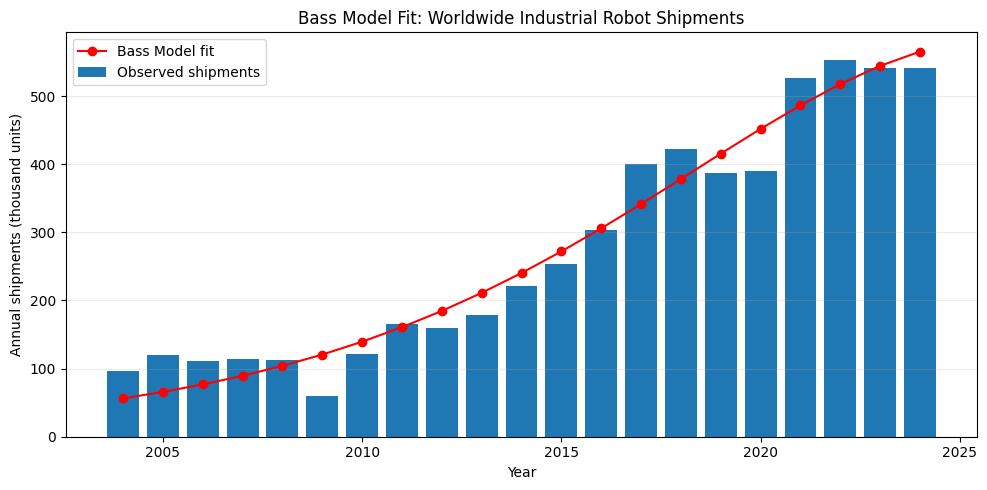

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(years, sales, label="Observed shipments")
plt.plot(years, fitted, color="red", marker="o",
         label="Bass Model fit")

plt.title("Bass Model Fit: Worldwide Industrial Robot Shipments")
plt.xlabel("Year")
plt.ylabel("Annual shipments (thousand units)")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("industrial_robot_bass_fit.png", dpi=200)
plt.show()


In [29]:

forecast_years = np.arange(2025, 2041)

all_t = np.arange(1, len(sales) + len(forecast_years) + 1)
all_cumulative = bass_cumulative(all_t, p, q, M)

forecast_cumulative = all_cumulative[len(sales):]
previous_cumulative = np.r_[all_cumulative[len(sales)-1],
                            forecast_cumulative[:-1]]

forecast_table = pd.DataFrame({
    "Year": forecast_years,
    "Predicted annual shipments (thousand)":
        forecast_cumulative - previous_cumulative,
    "Predicted cumulative shipments (thousand)":
        forecast_cumulative
})

display(forecast_table.round(2))

forecast_table.to_csv("industrial_robot_forecast_2025_2040.csv",
                      index=False)


,Year,Predicted annual shipments (thousand),Predicted cumulative shipments (thousand)
0,2025,579.53,6308.53
1,2026,586.11,6894.64
2,2027,584.79,7479.43
3,2028,575.65,8055.08
4,2029,559.16,8614.24
5,2030,536.17,9150.41
6,2031,507.80,9658.21
7,2032,475.31,10133.52
8,2033,440.03,10573.55
9,2034,403.25,10976.80



 M = 10 million | p = 0.001845


,Year,Predicted annual shipments,Predicted cumulative shipments
0,2025,20000.0,20000.0
1,2026,23438.0,43438.0
2,2027,27445.0,70883.0
5,2030,43808.0,184329.0
10,2035,92470.0,536314.0
15,2040,180665.0,1245428.0



 M = 30 million | p = 0.000615


,Year,Predicted annual shipments,Predicted cumulative shipments
0,2025,20000.0,20000.0
1,2026,23477.0,43477.0
2,2027,27551.0,71028.0
5,2030,44441.0,185701.0
10,2035,97513.0,551099.0
15,2040,208162.0,1339651.0



 M = 100 million | p = 0.000184


,Year,Predicted annual shipments,Predicted cumulative shipments
0,2025,20000.0,20000.0
1,2026,23491.0,43491.0
2,2027,27588.0,71079.0
5,2030,44665.0,186185.0
10,2035,99368.0,556461.0
15,2040,219210.0,1376037.0


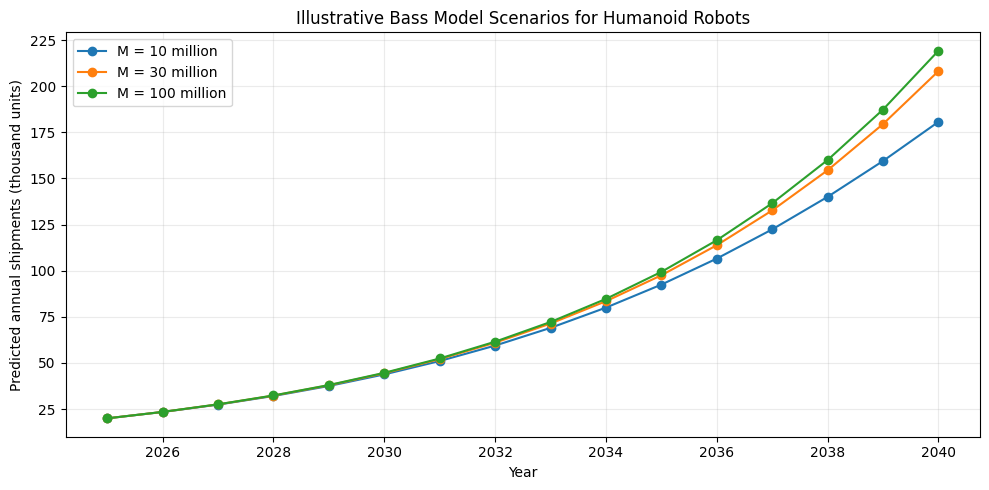

Saved humanoid_robot_scenarios.csv


In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

q_h = q

baseline_2025 = 20000

forecast_years = np.arange(2025, 2041)
t = np.arange(1, len(forecast_years) + 1)

def bass_cumulative(t, p, q, M):
    e = np.exp(-(p + q) * np.asarray(t))
    return M * (1 - e) / (1 + (q / p) * e)

def bass_annual(t, p, q, M):
    return bass_cumulative(t, p, q, M) - bass_cumulative(t - 1, p, q, M)

market_potentials = [10_000_000, 30_000_000, 100_000_000]

scenario_results = {}

for market in market_potentials:
    p_h = brentq(
        lambda p: bass_annual(1, p, q_h, market) - baseline_2025,
        1e-8, 0.5
    )

    annual = bass_annual(t, p_h, q_h, market)
    cumulative = np.cumsum(annual)

    scenario_results[f"M = {market / 1e6:g} million"] = {
        "p": p_h,
        "annual": annual,
        "cumulative": cumulative
    }

selected_years = [2025, 2026, 2027, 2030, 2035, 2040]

for name, result in scenario_results.items():
    table = pd.DataFrame({
        "Year": forecast_years,
        "Predicted annual shipments": result["annual"],
        "Predicted cumulative shipments": result["cumulative"]
    })

    print("\n", name, "| p =", round(result["p"], 6))
    display(table[table["Year"].isin(selected_years)].round(0))

plt.figure(figsize=(10, 5))

for name, result in scenario_results.items():
    plt.plot(
        forecast_years,
        result["annual"] / 1000,
        marker="o",
        label=name
    )

plt.title("Illustrative Bass Model Scenarios for Humanoid Robots")
plt.xlabel("Year")
plt.ylabel("Predicted annual shipments (thousand units)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("humanoid_robot_scenarios.png", dpi=200)
plt.show()

rows = []

for name, result in scenario_results.items():
    for i, year in enumerate(forecast_years):
        rows.append({
            "Scenario": name,
            "Year": year,
            "Annual shipments": result["annual"][i],
            "Cumulative shipments": result["cumulative"][i],
            "Assumed initial shipments in 2025": baseline_2025
        })

humanoid_forecast = pd.DataFrame(rows)
humanoid_forecast.to_csv("humanoid_robot_scenarios.csv", index=False)

print("Saved humanoid_robot_scenarios.csv")


In [31]:
from google.colab import files

files.download("humanoid_robot_scenarios.csv")
files.download("humanoid_robot_scenarios.png")
files.download("industrial_robot_forecast_2025_2040.csv")
files.download("industrial_robot_bass_fit.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>